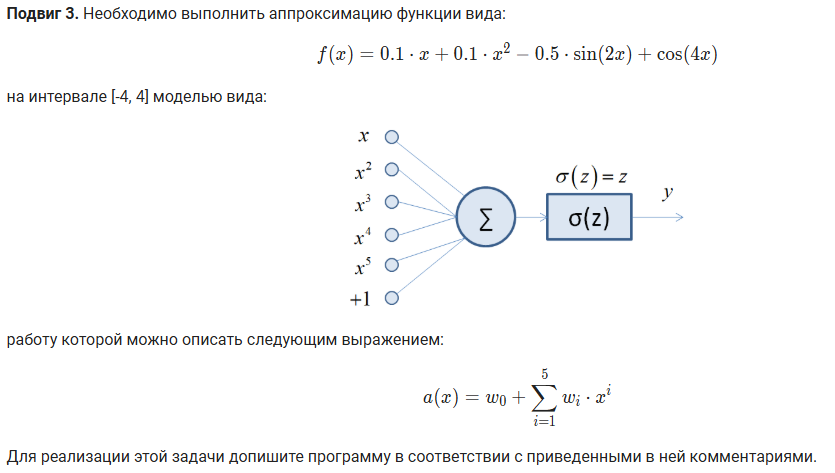

In [18]:
import torch
import torch.utils.data as data
import torch.nn as nn
import torch.optim as optim

class FuncModel(nn.Module):
    def __init__(self, in_features):
        super().__init__()
        self.layer = nn.Linear(in_features, 1, bias=True) # полносвязный слой: число входов in_features, число нейронов 1

    def forward(self, x):
        return self.layer(x)


torch.manual_seed(1)

epochs = 20 # число эпох обучения
batch_size = 8 # размер батча
N = 6 # порядок модели (N-1)

# формирование обучающей выборки (значений функции)
data_x = torch.arange(-4, 4, 0.01)
data_y = 0.1 * data_x + 0.1 * data_x ** 2 - 0.5 * torch.sin(2 * data_x) + torch.cos(4 * data_x)
data_x.unsqueeze_(-1)
X = torch.cat([data_x ** _n for _n in range(N)], dim=1)
ds = data.TensorDataset(X, data_y)

d_train, d_val = data.random_split(ds, [0.8, 0.2]) # разделите выборку ds на две части в пропорции: 80% и 20%
train_data = data.DataLoader(d_train, batch_size=batch_size, shuffle=True)
train_data_val = data.DataLoader(d_val, batch_size=len(d_val), shuffle=False)

model = FuncModel(N)
optimizer = optim.RMSprop(model.parameters(), lr=0.01, weight_decay=10) # создайте оптимизатор RMSprop для модели model с шагом обучения 0.01 и weight_decay=10
loss_func = nn.MSELoss() # сформируйте функцию потерь с помощью класса MSELoss

loss_lst_val = []  # список значений потерь при валидации
loss_lst = []  # список значений потерь при обучении

for _e in range(epochs):
    # переведите модель в режим обучения
    model.train()
    loss_mean = 0
    lm_count = 0

    for x_train, y_train in train_data:
        optimizer.zero_grad()
        # print(x_train.shape)
        predict = model(x_train).squeeze() # вычислите прогноз модели для x_train
        loss = loss_func(predict, y_train) # вычислите потери для predict и y_train

        # выполните один шаг обучения (градиентного спуска)
        loss.backward()
        optimizer.step()

        lm_count += 1
        loss_mean = 1 / lm_count * loss.item() + (1 - 1 / lm_count) * loss_mean

    # валидация модели
    # переведите модель в режим эксплуатации
    model.eval()
    x_val, y_val = next(iter(train_data_val))

    with torch.no_grad():
        p = model(x_val).squeeze() # вычислите прогноз модели для x_val
        loss = loss_func(p, y_val) # вычислите потери для p и y_val
        Q_val = loss.item()

    loss_lst.append(loss_mean)
    loss_lst_val.append(Q_val)

# переведите модель в режим эксплуатации
model.eval()
p = model(X).squeeze() # вычислите прогноз модели по всем данным выборки X
Q = loss_func(p, data_y).item() # вычислите потери с помощью loss_func для p и data_y; значение Q сохраните в виде вещественного числа
Q

0.6522691249847412

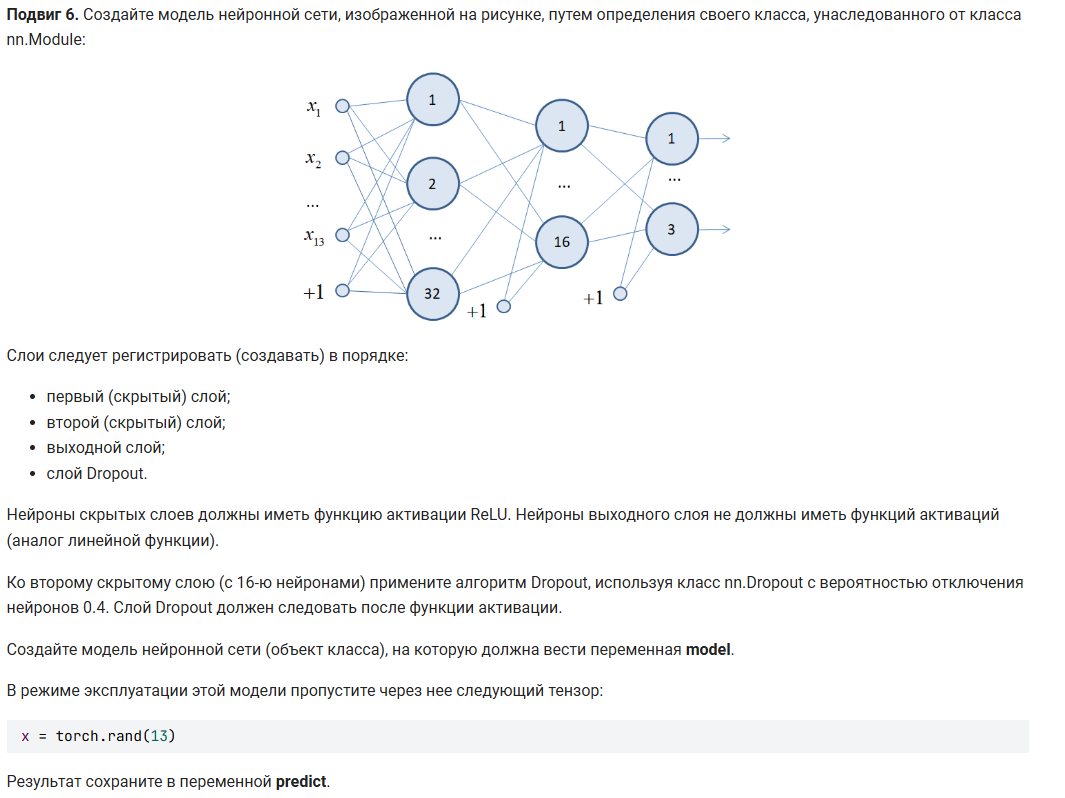

In [34]:
import torch
import torch.nn as nn

# здесь объявляйте класс модели (обязательно до тензора x)
class MyModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer1 = nn.Linear(13, 32)
        self.layer2 = nn.Linear(32, 16)
        self.layer3 = nn.Linear(16, 3)
        self.dropout = nn.Dropout(0.4)
        self.activation = nn.ReLU()

    def forward(self, x):
        x = self.layer1(x)
        x = self.activation(x)
        x = self.layer2(x)
        x = self.activation(x)
        x = self.dropout(x)
        x = self.layer3(x)
        return x

model = MyModel() # здесь создавайте объект модели

x = torch.rand(13).unsqueeze(0)

# здесь продолжайте программу для вычисления predict
predict = model(x)

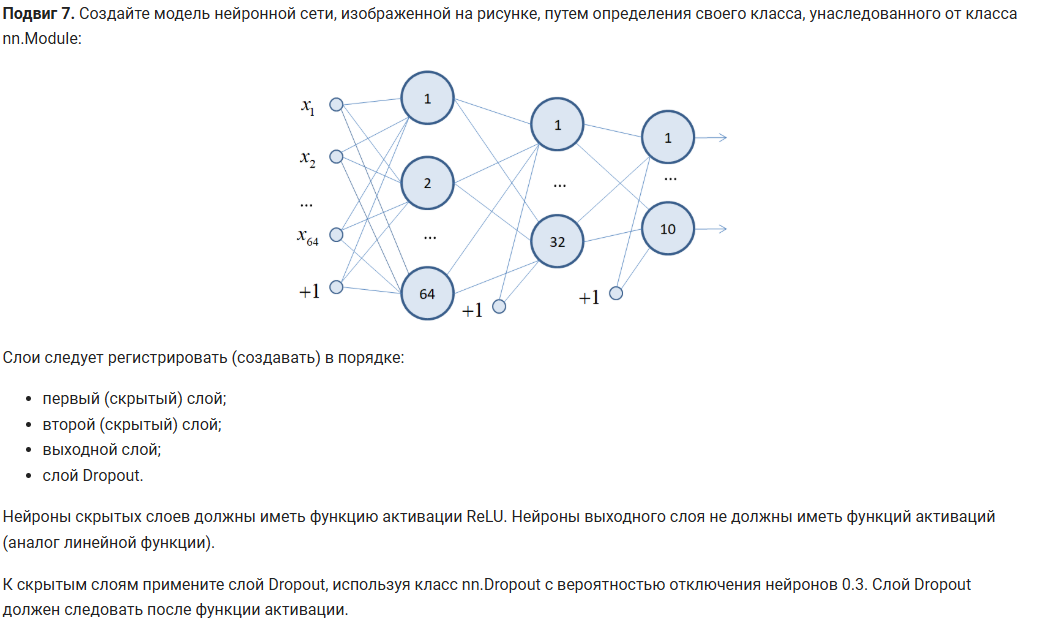

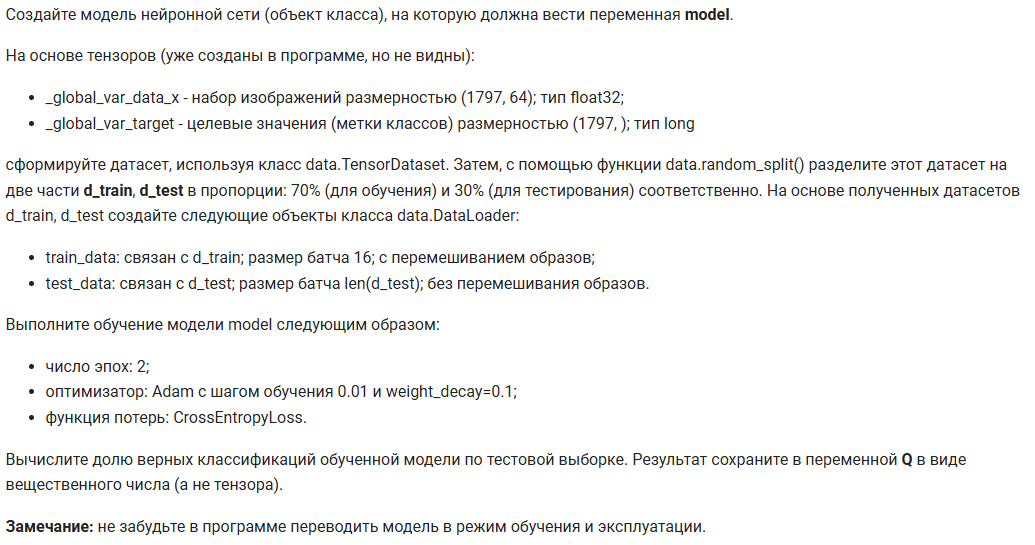

In [74]:
import torch
import torch.utils.data as data
import torch.nn as nn
import torch.optim as optim
from sklearn.datasets import load_digits

digits = load_digits()

# Признаки и целевые значения
_global_var_data_x = torch.tensor(digits.data, dtype=torch.float32)
_global_var_target = torch.tensor(digits.target, dtype=torch.int64)


# здесь продолжайте программу
class MyModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer1 = nn.Linear(64, 64)
        self.layer2 = nn.Linear(64, 32)
        self.layer3 = nn.Linear(32, 10)
        self.dropout = nn.Dropout(0.3)
        self.activation = nn.ReLU()

    def forward(self, x):
        x = self.layer1(x)
        x = self.activation(x)
        x = self.dropout(x)
        x = self.layer2(x)
        x = self.activation(x)
        x = self.dropout(x)
        x = self.layer3(x)
        return x


model = MyModel()

dataset = data.TensorDataset(_global_var_data_x, _global_var_target)

d_train, d_test = data.random_split(dataset, [0.7, 0.3])

train_data = data.DataLoader(d_train, batch_size=16, shuffle=True)
test_data = data.DataLoader(d_test, batch_size=len(d_test), shuffle=False)

optimizer = optim.Adam(model.parameters(), lr=0.01, weight_decay=0.1)
loss_func = nn.CrossEntropyLoss()

epochs = 2

for e in range(epochs):

    model.train()
    for x_train, y_train in train_data:
        optimizer.zero_grad()
        y_pred = model(x_train) #.squeeze()

        loss = loss_func(y_pred, y_train)
        loss.backward()
        optimizer.step()


x_test, y_test = next(iter(test_data))

model.eval()
y_pred = model(x_test)
y_pred = torch.argmax(y_pred, dim=1)
Q = torch.mean((y_test==y_pred).float()).item()
Q



0.8589981198310852